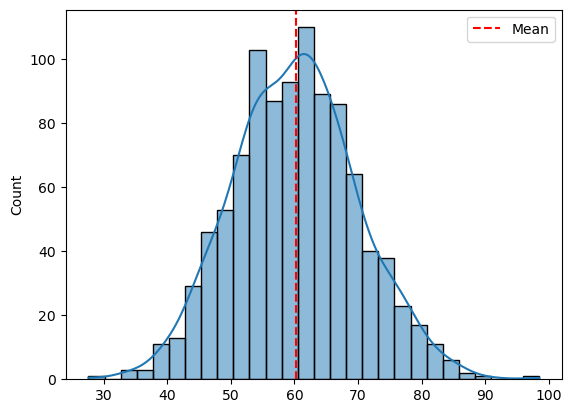

0.9772498680518208
0.6826894921370859
Outliers: 3
Shapiro p-value: 0.6272578290246378


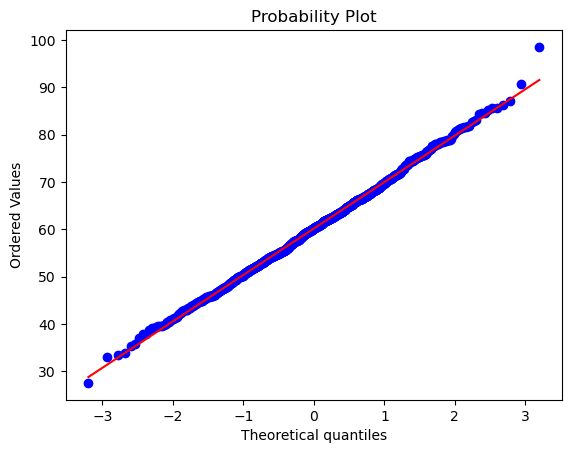

-1.0480505352461477e-16 1.0


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

# 1. Normal data generate karna
np.random.seed(42)
data = np.random.normal(loc=60, scale=10, size=1000)

# 2. Plot
sns.histplot(data, kde=True)
plt.axvline(data.mean(), color='red', linestyle='--', label='Mean')
plt.legend()
plt.show()

# 3. Probability nikalna (scipy.stats.norm)
# P(marks < 80)?
print(stats.norm.cdf(80, loc=60, scale=10))        # ~0.977

# P(50 < marks < 70)?
print(stats.norm.cdf(70, 60, 10) - stats.norm.cdf(50, 60, 10))  # ~0.683

# 4. Z-score aur outlier detection
z = stats.zscore(data)
outliers = data[np.abs(z) > 3]
print("Outliers:", len(outliers))

# 5. Kya data normal hai? (Normality tests)
stat, p = stats.shapiro(data)
print("Shapiro p-value:", p)   # p > 0.05 => normal maana ja sakta hai

# Visual check: Q-Q plot
stats.probplot(data, dist="norm", plot=plt)
plt.show()

# 6. Standardization (sklearn)
from sklearn.preprocessing import StandardScaler
scaled = StandardScaler().fit_transform(data.reshape(-1, 1))
print(scaled.mean(), scaled.std())   # ~0 aur ~1

In [2]:
np.random.seed(42)
data = np.random.normal(loc=60, scale=10, size=1000)

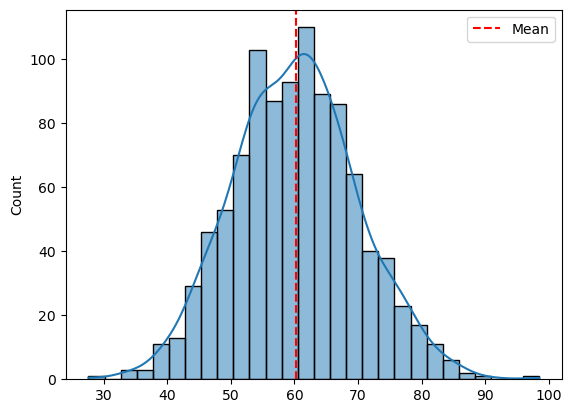

In [4]:

sns.histplot(data, kde=True)
plt.axvline(data.mean(), color='red', linestyle='--', label='Mean')
plt.legend()
plt.show()

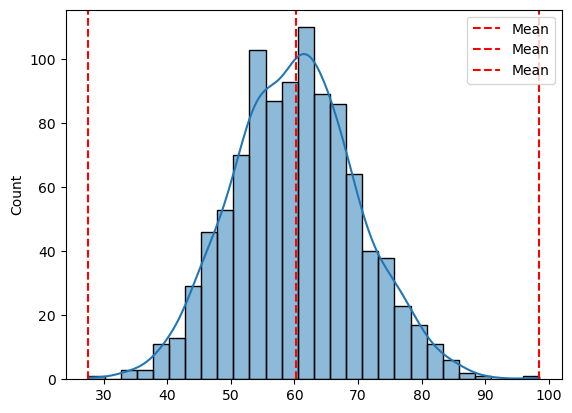

In [12]:

sns.histplot(data, kde=True)
plt.axvline(data.min(), color='red', linestyle='--', label='Mean')
plt.axvline(np.median(data), color='red', linestyle='--', label='Mean')
plt.axvline(data.max(), color='red', linestyle='--', label='Mean')
plt.legend()
plt.show()

In [17]:
# 4. Z-score aur outlier detection
z = stats.zscore(data)
outliers = data[np.abs(z) > 3]
print("Outliers:", len(outliers))

Outliers: 3


In [22]:
outliers

array([98.52731491, 27.5873266 , 90.78880808])

In [23]:
q1, q3 = np.percentile(data, [25, 75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = data[(data < lower) | (data > upper)]
print("IQR Outliers:", outliers)   # 500 aur 600 pakad lega


IQR Outliers: [33.80254896 87.20169167 98.52731491 27.5873266  90.78880808 33.03113357
 33.49030192 86.32382065]


In [24]:
median = np.median(data)
mad = np.median(np.abs(data - median))
modified_z = 0.6745 * (data - median) / mad
outliers = data[np.abs(modified_z) > 3.5]   # threshold 3.5
print("MAD Outliers:", outliers)


MAD Outliers: [98.52731491]


In [25]:
from sklearn.ensemble import IsolationForest
import pandas as pd

df = pd.DataFrame({"age": [25, 30, 28, 5, 32], "salary": [40, 50, 45, 100, 55]})
iso = IsolationForest(contamination=0.1, random_state=42)
df["outlier"] = iso.fit_predict(df)    # -1 = outlier, 1 = normal
print(df)

   age  salary  outlier
0   25      40        1
1   30      50        1
2   28      45        1
3    5     100       -1
4   32      55        1


In [26]:
from sklearn.ensemble import IsolationForest
import pandas as pd

df = pd.DataFrame(data)
iso = IsolationForest(contamination=0.1, random_state=42)
df["outlier"] = iso.fit_predict(df)    # -1 = outlier, 1 = normal
print(df)

             0  outlier
0    64.967142        1
1    58.617357        1
2    66.476885        1
3    75.230299        1
4    57.658466        1
..         ...      ...
995  57.188997        1
996  77.976865       -1
997  66.408429        1
998  54.288210        1
999  65.725828        1

[1000 rows x 2 columns]


In [28]:
from sklearn.neighbors import LocalOutlierFactor
lof = LocalOutlierFactor(n_neighbors=3)
labels = lof.fit_predict(data)   # -1 = outlier

ValueError: Expected 2D array, got 1D array instead:
array=[64.96714153 58.61735699 66.47688538 75.23029856 57.65846625 57.65863043
 75.79212816 67.67434729 55.30525614 65.42560044 55.36582307 55.34270246
 62.41962272 40.86719755 42.75082167 54.37712471 49.8716888  63.14247333
 50.91975924 45.87696299 74.65648769 57.742237   60.67528205 45.75251814
 54.55617275 61.1092259  48.49006423 63.75698018 53.9936131  57.0830625
 53.98293388 78.52278185 59.86502775 49.42289071 68.22544912 47.7915635
 62.08863595 40.40329876 46.71813951 61.96861236 67.3846658  61.71368281
 58.84351718 56.98896304 45.2147801  52.80155792 55.39361229 70.57122226
 63.4361829  42.36959845 63.24083969 56.1491772  53.23078    66.11676289
 70.30999522 69.31280119 51.60782477 56.90787624 63.31263431 69.75545127
 55.20825762 58.14341023 48.93665026 48.03793376 68.12525822 73.56240029
 59.27989878 70.03532898 63.61636025 53.54880245 63.61395606 75.38036566
 59.64173961 75.64643656 33.80254896 68.21902504 60.87047068 57.009

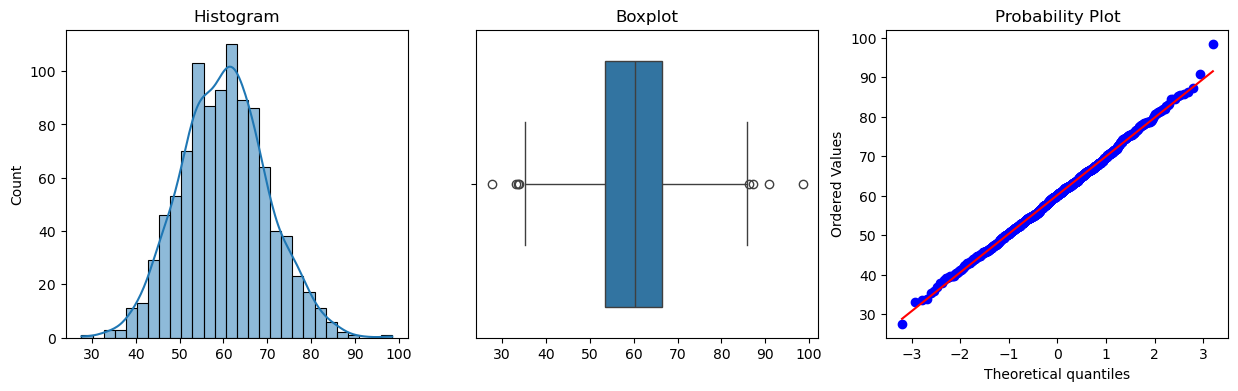

Skew: 0.11680083110533479
Kurtosis: 0.06620589292148438
Median: 60.25300612234888 Mean: 60.193320558223256


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data, kde=True, ax=ax[0]); ax[0].set_title("Histogram")
sns.boxplot(x=data, ax=ax[1]);          ax[1].set_title("Boxplot")
stats.probplot(data, dist="norm", plot=ax[2])
plt.show()

print("Skew:", stats.skew(data))
print("Kurtosis:", stats.kurtosis(data))
print("Median:", np.median(data), "Mean:", data.mean())